# MotoRadar — Cuaderno del TFM

**Previsión de la demanda de motos por provincia y carnet para planificar el stock de un concesionario**
Juanjo · Máster en Data Science & IA · Evolve Academy

Este cuaderno recorre el proyecto de principio a fin con las salidas del pipeline. El código "de verdad" está en scripts `.py` reproducibles (`pipeline/`) y en el paquete `motoradar/`; aquí solo se leen y se comentan sus resultados.

> Para regenerar todo: `python pipeline/ejecutar_todo.py` (unos 8 minutos).

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import pandas as pd
from IPython.display import Image, display
from motoradar import datos as D
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
FIG = D.FIGURES

## 1. Datos

Fuente: **microdatos de matriculaciones de la DGT**, un fichero mensual con todos los vehículos matriculados en España. La fase 0 (`pipeline/fase0_descarga_dgt.py`) descarga los ZIP, se queda con motos y ciclomotores, clasifica cada moto por el carnet que exige y agrega por mes, provincia y segmento.

In [2]:
prov = D.leer_provincia_segmento()
print(f"{prov['mes'].min()} a {prov['mes'].max()} · {prov['mes'].nunique()} meses · "
      f"{prov['provincia'].nunique()} provincias · {prov['segmento'].nunique()} segmentos")
print(f"Motos nuevas: {prov['matriculaciones'].sum():,}".replace(",", "."))
prov.tail()

2015-01 a 2026-08 · 140 meses · 52 provincias · 4 segmentos
Motos nuevas: 2.305.568


,mes,provincia,segmento,matriculaciones
29115,2026-04,ZA,A,16
29116,2026-05,ZA,A,14
29117,2026-06,ZA,A,22
29118,2026-07,ZA,A,9
29119,2026-08,ZA,A,4


### Controles de calidad

In [3]:
pd.read_csv(D.RESULTS / "controles_calidad.csv")

,control,superado
0,Meses consecutivos sin huecos,True
1,52 provincias x 4 segmentos,True
2,Todas las provincias tienen nombre,True
3,Sin valores negativos,True
4,Suma provincial = total nacional (motos nuevas),True
5,Suma por marcas = total nacional (motos nuevas),True
6,Abril 2020 es el mínimo de la serie (confinami...,True


## 2. Análisis exploratorio

In [4]:
pd.read_csv(D.RESULTS / "hallazgos_eda.csv")

,hallazgo,dato
0,Crecimiento 2015-2025,"147,966 -> 253,577 (+71%)"
1,Enero-agosto 2026 frente a 2025,"201,216 frente a 166,463 (+20.9%)"
2,Cuota ciclomotores (AM),10.8 % en 2015 -> 4.7 % en 2026
3,Cuota A2,20.0 % en 2015 -> 25.1 % en 2026
4,Mes pico por segmento,"AM: 7, A1: 7, A2: 7, A: 5"
5,Cuota nuevas marcas chinas,0.6 % en 2020 -> 24.8 % en 2026
6,Concentración geográfica,Barcelona + Madrid = 27% del mercado; top 10 =...
7,Cuota eléctricas,máximo 8.5 % en 2020; 3.0 % en 2026
8,Matriculadas por empresas,"18.0 % en 2020 -> 10.1 % en 2026 (renting, flo..."
9,Meses con más motos a nombre de empresa,"2024-12 (8,965), 2016-12 (7,127), 2023-05 (4,8..."


El mercado ha crecido un 71 % entre 2015 y 2025 y sigue acelerando en 2026.

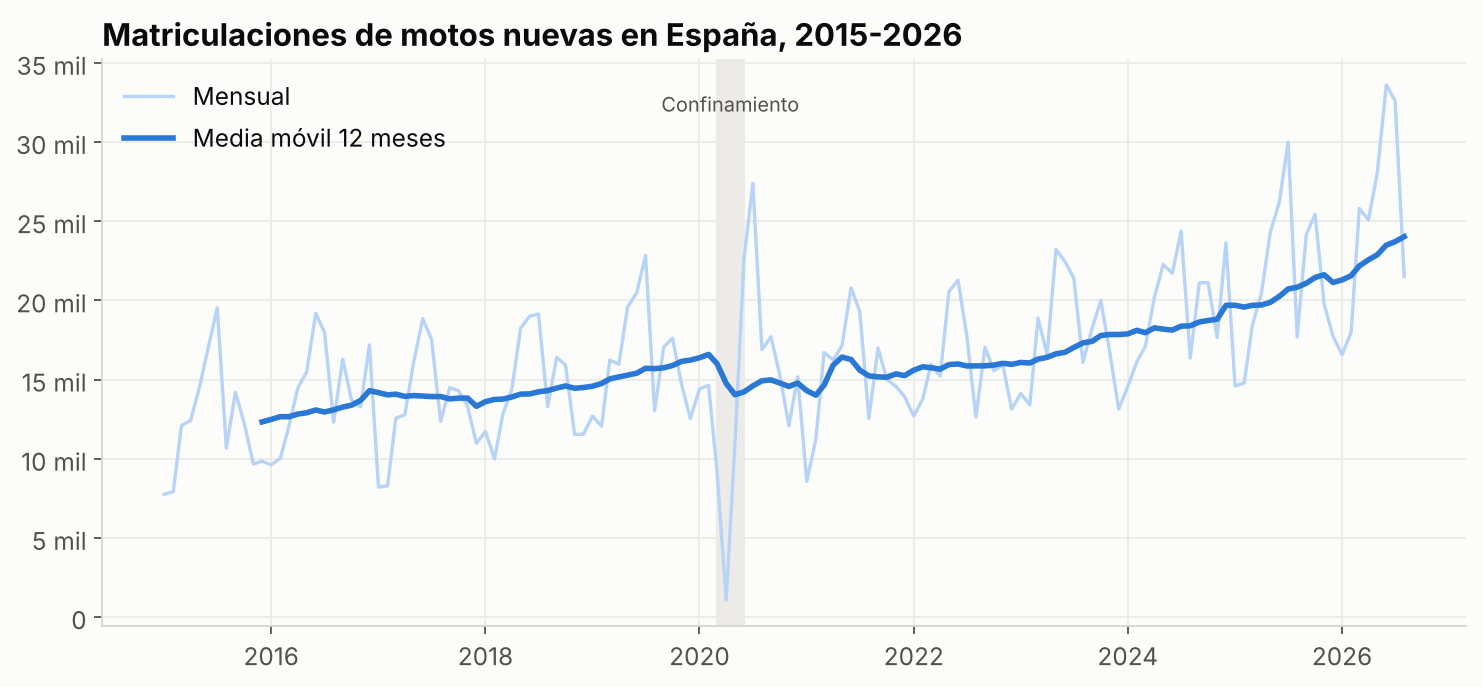

In [5]:
display(Image(FIG / "01_evolucion_mercado.png", width=900))

Los ciclomotores se hunden y el A2 gana peso: el comprador sube de cilindrada.

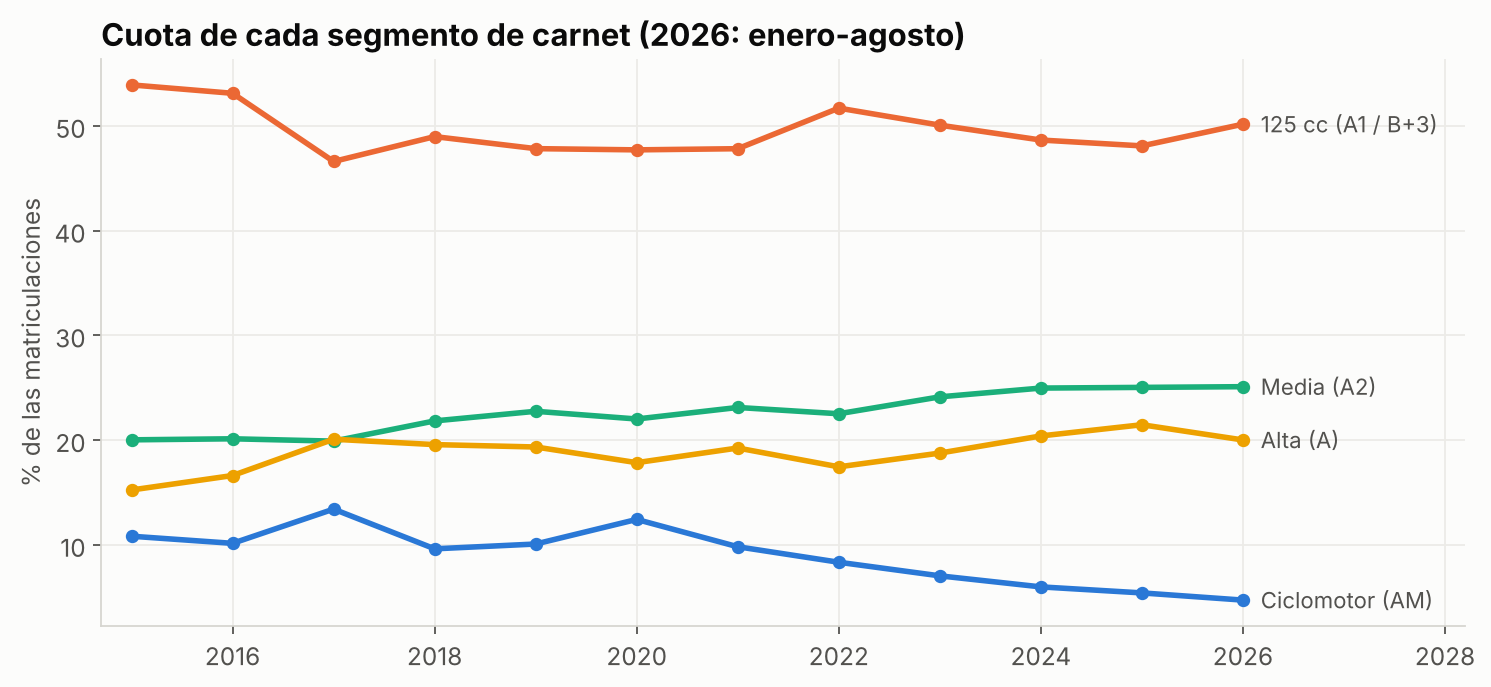

In [6]:
display(Image(FIG / "02_mix_segmentos.png", width=900))

Fuerte estacionalidad: pico en primavera-verano, valle en invierno.

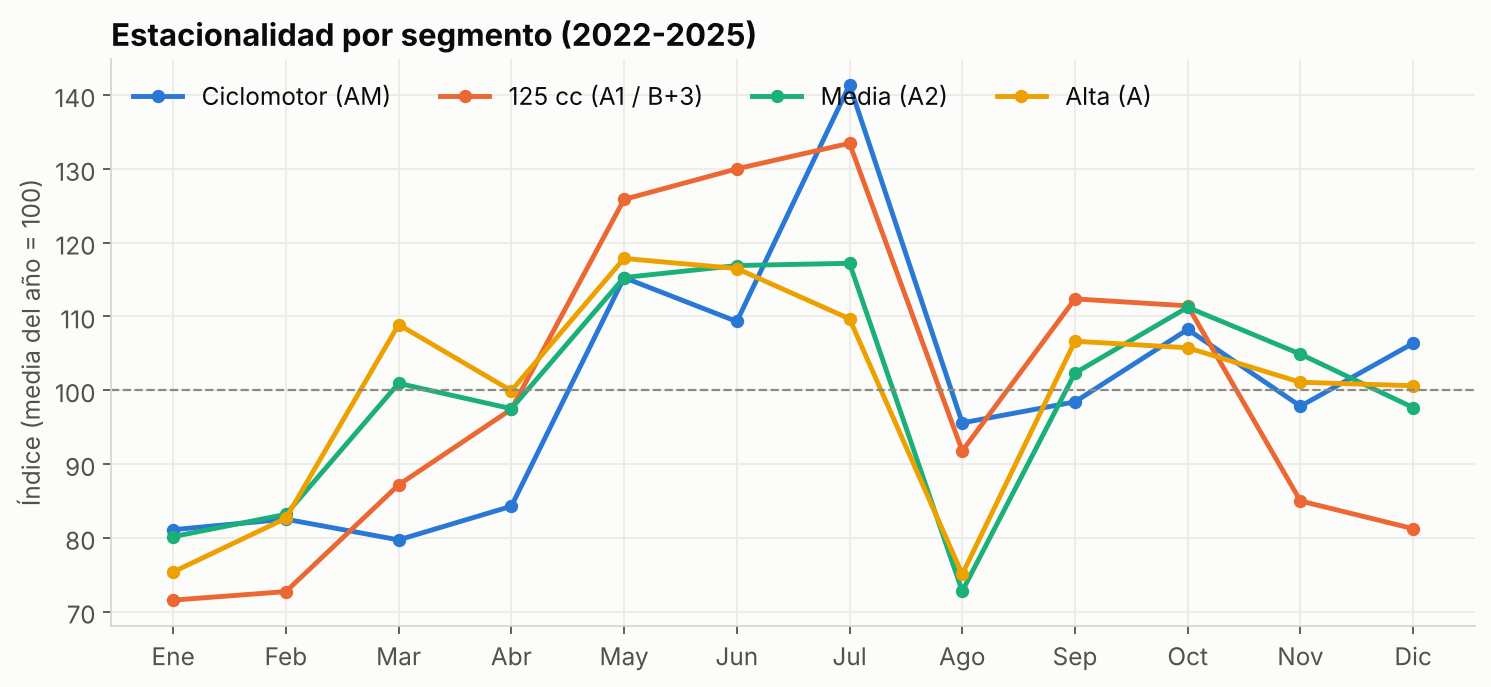

In [7]:
display(Image(FIG / "03_estacionalidad.png", width=900))

La gran disrupción: las nuevas marcas chinas pasan de casi 0 a una de cada cuatro motos.

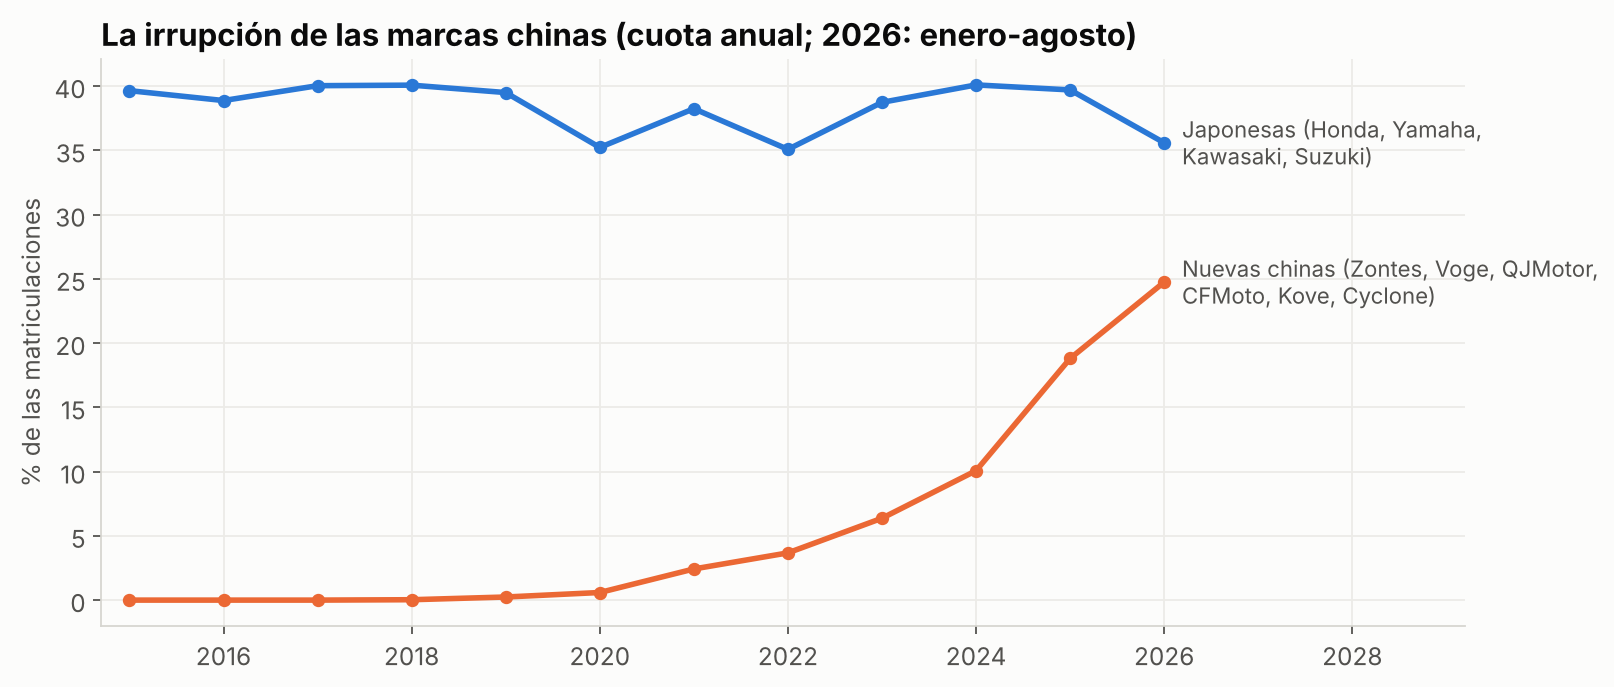

In [8]:
display(Image(FIG / "04_marcas_chinas.png", width=900))

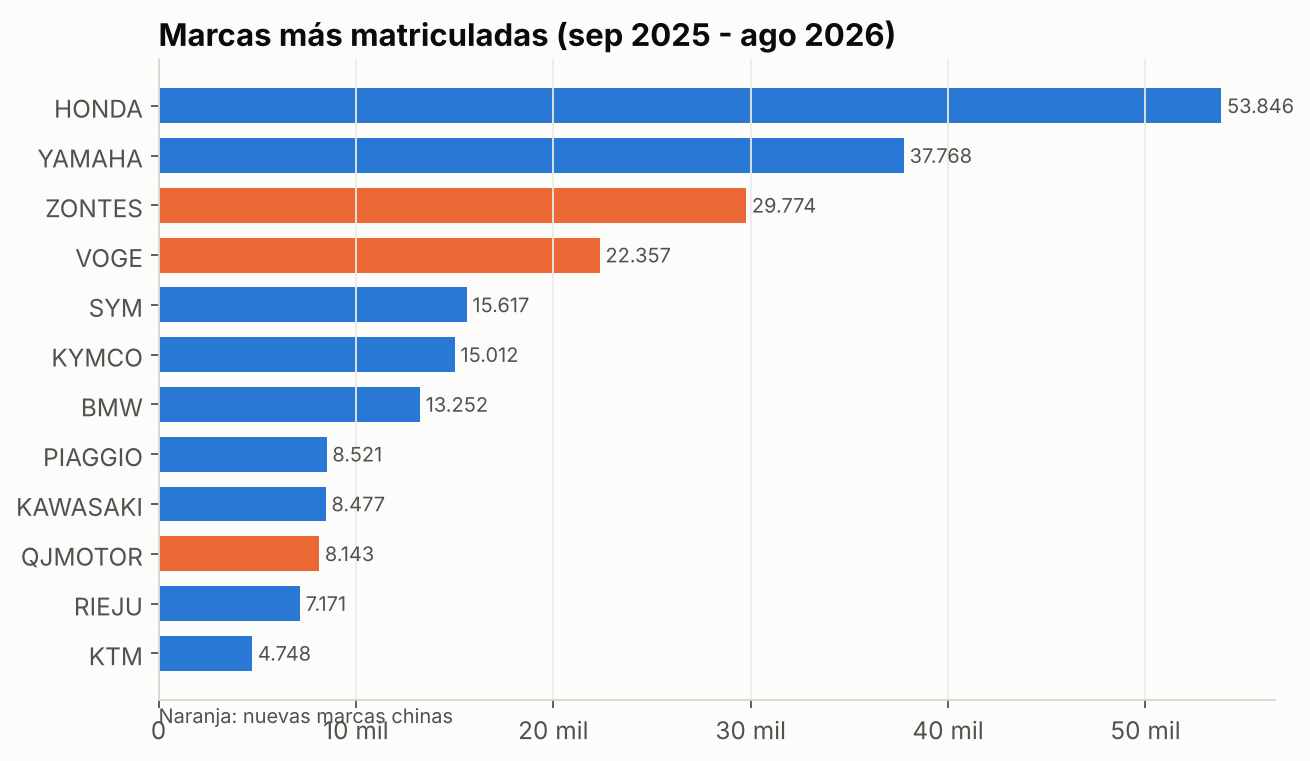

In [9]:
display(Image(FIG / "05_ranking_marcas.png", width=900))

Mercado muy concentrado: Barcelona y Madrid suman el 27 %.

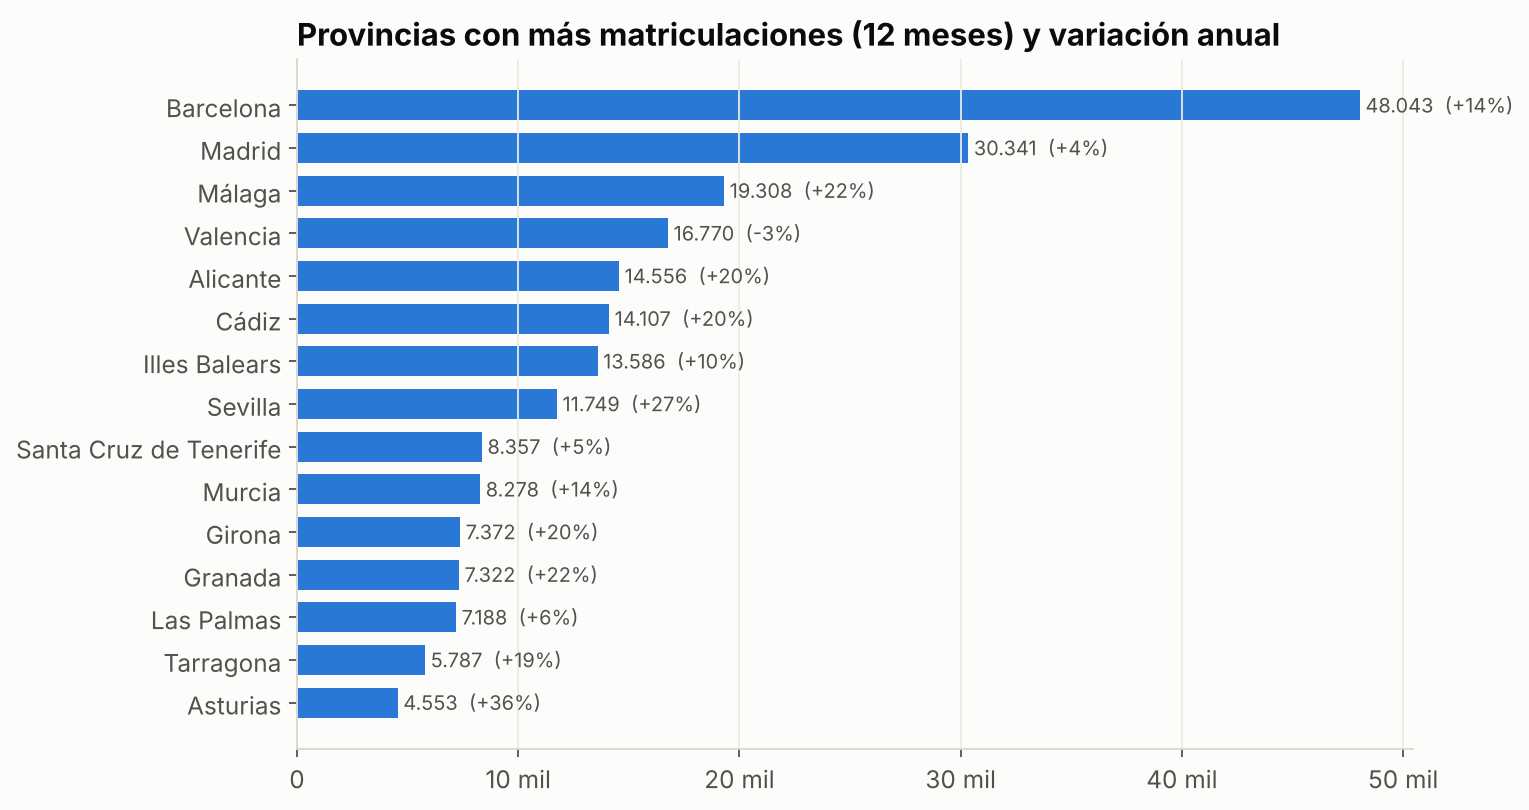

In [10]:
display(Image(FIG / "06_provincias.png", width=900))

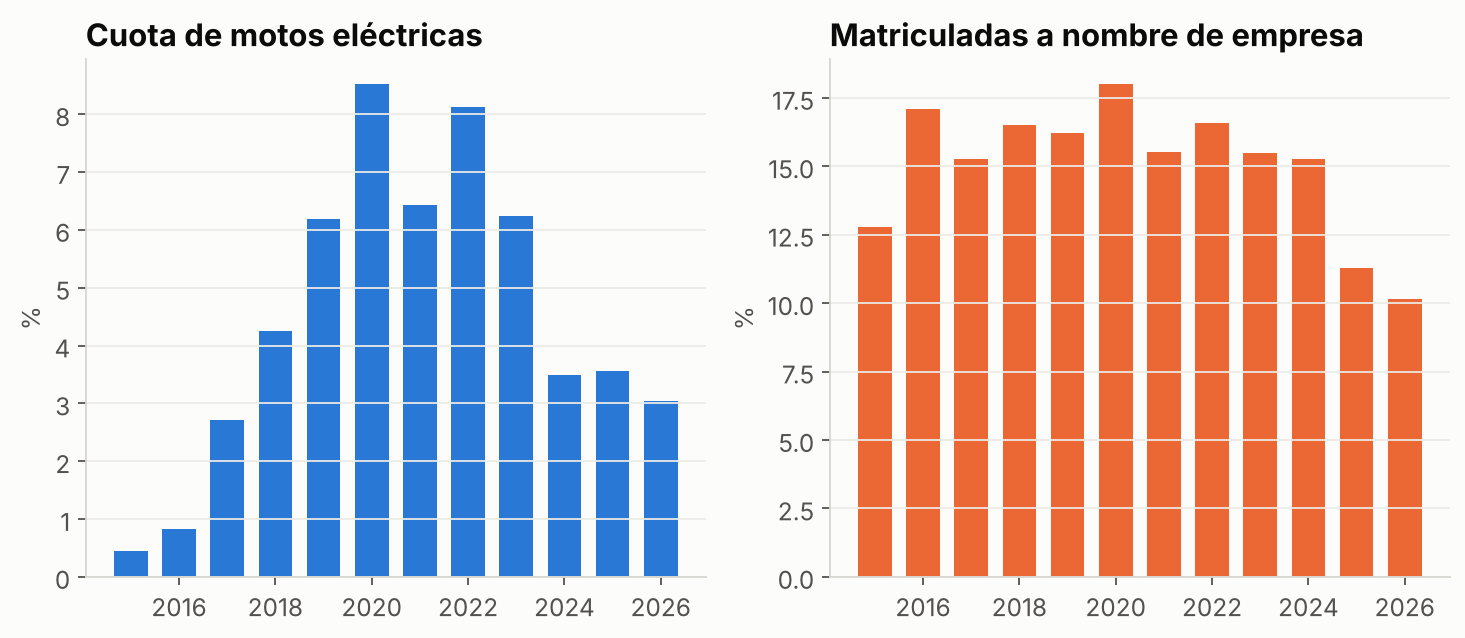

In [11]:
display(Image(FIG / "07_electricas_empresas.png", width=900))

## 3. Modelado

Cuatro modelos, de menos a más sofisticado, evaluados con **validación de origen móvil**: 23 meses (sep 2024 - jul 2026) en los que se reentrena con lo que se sabía ese mes y se predicen los 3 siguientes. Métrica: **WAPE** (de cada 100 motos, en cuántas se equivoca la previsión).

In [12]:
pd.read_csv(D.RESULTS / "comparativa_modelos.csv")

,modelo,wape_provincia,wape_nacional,mae_provincia,sesgo
0,Naive estacional (año anterior),0.214,0.167,23.247,0.128
1,Naive estacional con tendencia,0.227,0.162,24.652,-0.005
2,Holt-Winters (ETS),0.185,0.137,20.105,0.113
3,LightGBM global,0.152,0.103,16.522,0.050


In [13]:
pd.read_csv(D.RESULTS / "mejora_bootstrap.csv")

,referencia,mejora,ic95_inf,ic95_sup
0,Naive estacional (año anterior),0.289,0.225,0.353
1,Naive estacional con tendencia,0.330,0.264,0.390
2,Holt-Winters (ETS),0.178,0.094,0.259


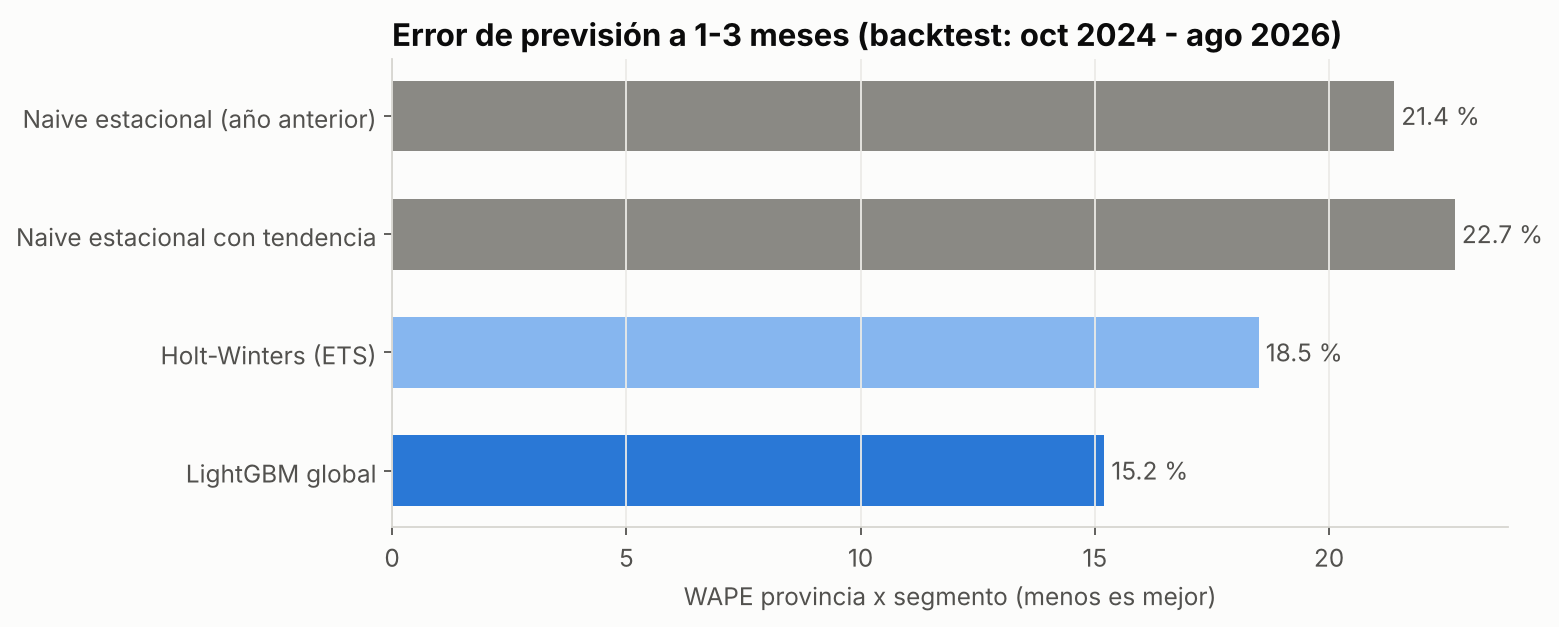

In [14]:
display(Image(FIG / "08_comparativa_modelos.png", width=800))

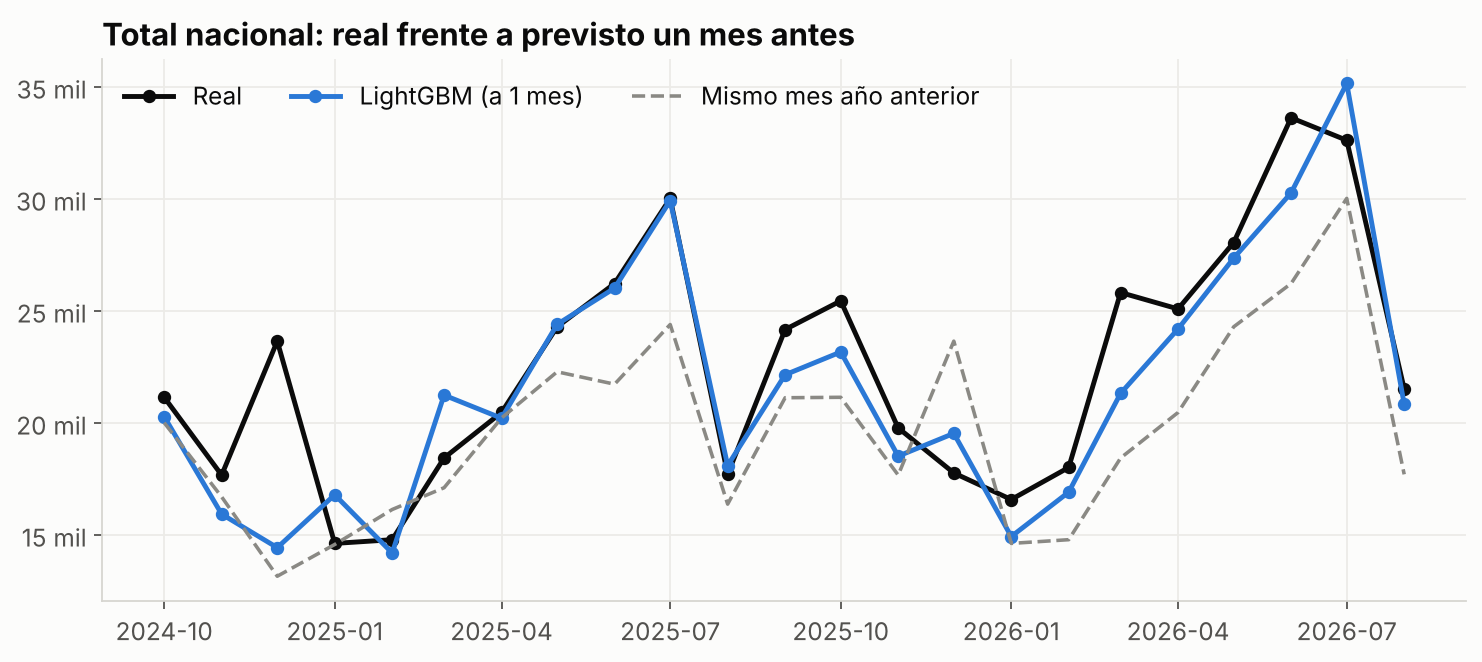

In [15]:
display(Image(FIG / "09_real_vs_previsto.png", width=900))

### Error por horizonte, segmento y tamaño de provincia

In [16]:
display(pd.read_csv(D.RESULTS / "wape_por_horizonte.csv"))
display(pd.read_csv(D.RESULTS / "wape_por_segmento.csv"))
display(pd.read_csv(D.RESULTS / "wape_por_tamano_provincia.csv"))

,h,Naive estacional (año anterior),Naive estacional con tendencia,Holt-Winters (ETS),LightGBM global
0,1,0.212,0.209,0.179,0.146
1,2,0.215,0.230,0.186,0.153
2,3,0.216,0.243,0.191,0.158


,segmento,Naive estacional (año anterior),Naive estacional con tendencia,Holt-Winters (ETS),LightGBM global
0,AM,0.340,0.398,0.278,0.261
1,A1,0.208,0.211,0.170,0.144
2,A2,0.215,0.237,0.192,0.147
3,A,0.195,0.209,0.189,0.149


,tamano,WAPE naive,WAPE ETS,WAPE LightGBM,provincias
0,Pequeñas,0.369,0.315,0.292,13.000
1,Medianas,0.271,0.231,0.209,13.000
2,Grandes,0.232,0.193,0.170,13.000
3,Muy grandes,0.198,0.173,0.136,13.000


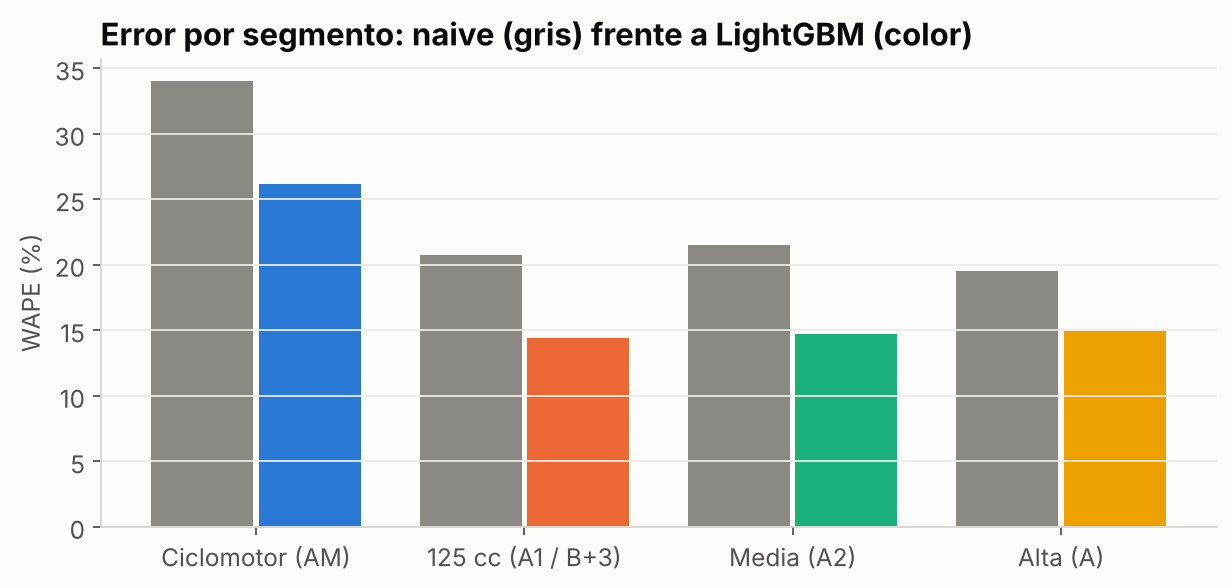

In [17]:
display(Image(FIG / "10_error_segmento.png", width=800))

### Intervalos de predicción y experimento de corrección de sesgo

In [18]:
display(pd.read_csv(D.RESULTS / "cobertura_intervalos.csv"))
display(pd.read_csv(D.RESULTS / "experimento_correccion_sesgo.csv"))

,segmento,cobertura_real
0,AM,0.812
1,A1,0.817
2,A2,0.858
3,A,0.765
4,Total,0.813


,variante,wape,sesgo
0,LightGBM,0.152,0.050
1,LightGBM con corrección de sesgo,0.163,-0.005


### Qué mira el modelo

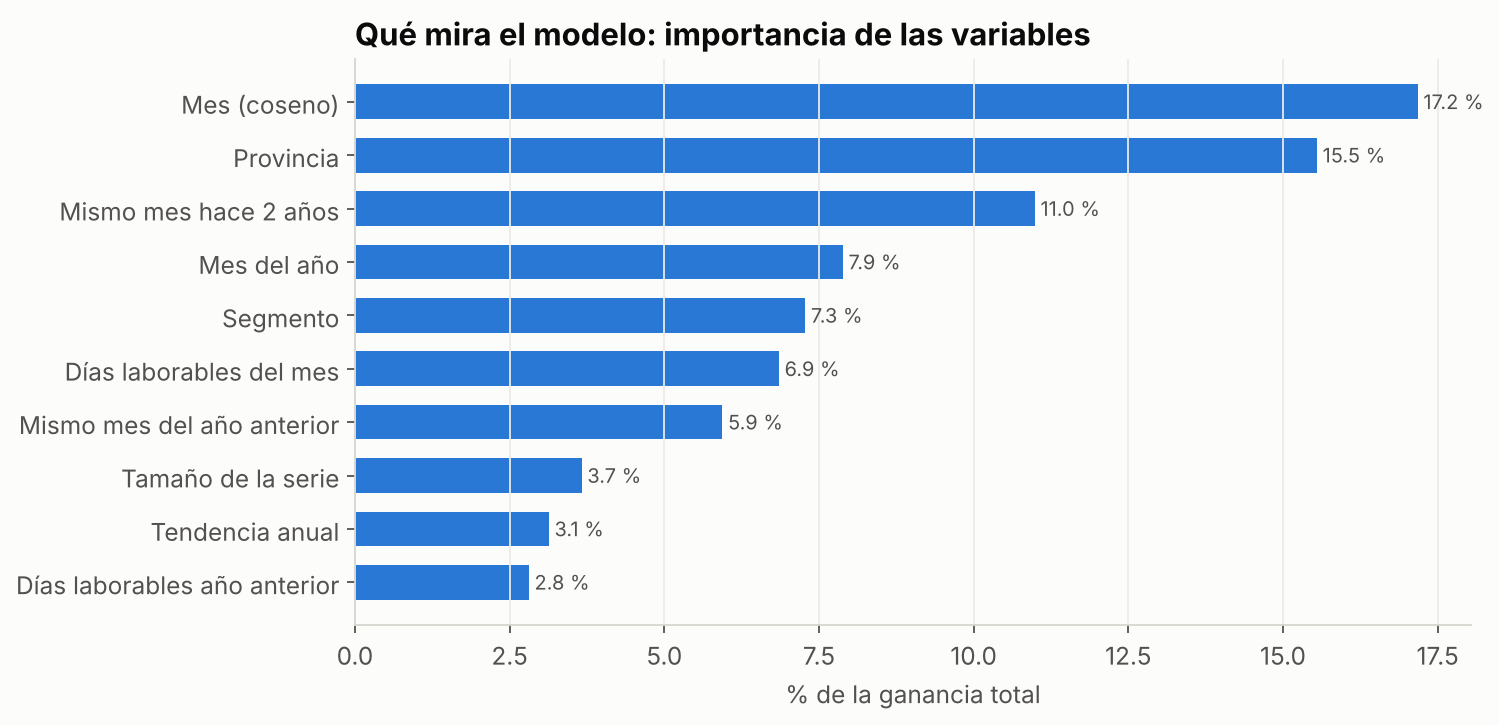

In [19]:
display(Image(FIG / "11_importancia_variables.png", width=800))

## 4. Previsión final (lo que ve el concesionario)

In [20]:
prev = pd.read_csv(D.GOLD / "previsiones.csv", keep_default_na=False)
print(json.dumps(json.loads((D.MODELS / "metadata.json").read_text())["backtest"], indent=2, ensure_ascii=False))
prev.groupby(["mes", "segmento"])[["prevision", "inf_80", "sup_80", "real_anio_anterior"]].sum().round(0)

{
  "origenes": "2024-09 a 2026-07",
  "wape_provincia_lightgbm": 0.152,
  "wape_provincia_naive": 0.2139,
  "wape_nacional_lightgbm": 0.1026,
  "mejora_vs_naive": 0.2893,
  "mejora_vs_naive_ic95": [
    0.2248,
    0.3533
  ],
  "cobertura_intervalo_80": 0.813,
  "wape_provincia_ets": 0.185,
  "mejora_vs_ets": 0.1782
}


prevision     inf_80     sup_80  real_anio_anterior
mes     segmento                                                     
2026-09 A         4,942.000  3,698.000  7,131.000                4838
        A1       12,583.000 10,360.000 18,589.000               12245
        A2        6,090.000  4,557.000  8,696.000                5840
        AM        1,220.000    744.000  2,157.000                1234
2026-10 A         4,932.000  3,709.000  7,219.000                5116
        A1       12,149.000 10,048.000 18,435.000               12463
        A2        6,255.000  4,689.000  9,032.000                6444
        AM        1,252.000    778.000  2,249.000                1413
2026-11 A         4,641.000  3,514.000  6,850.000                4680
        A1        9,877.000  8,025.000 15,082.000                8279
        A2        5,980.000  4,479.000  8,743.000                5239
        AM        1,120.000    678.000  2,031.000                1567

In [21]:
prev[prev["provincia"] == "M"]

,mes,h,provincia,nombre_provincia,segmento,prevision,inf_80,sup_80,naive_estacional,real_anio_anterior
336,2026-09,1,M,Madrid,A,672.600,504.700,967.700,596.000,596
337,2026-10,2,M,Madrid,A,690.300,520.700,"1,007.600",642.000,642
338,2026-11,3,M,Madrid,A,677.500,514.600,996.800,797.000,797
339,2026-09,1,M,Madrid,A1,"1,235.000","1,017.500","1,822.600","1,287.000",1287
340,2026-10,2,M,Madrid,A1,"1,198.600",992.000,"1,816.600","1,490.000",1490
341,2026-11,3,M,Madrid,A1,956.000,777.500,"1,457.700",818.000,818
342,2026-09,1,M,Madrid,A2,680.200,510.200,969.100,701.000,701
343,2026-10,2,M,Madrid,A2,687.200,516.300,990.200,719.000,719
344,2026-11,3,M,Madrid,A2,674.200,506.200,983.600,527.000,527
345,2026-09,1,M,Madrid,AM,57.300,35.500,100.200,65.000,65


## 5. Conclusiones

- Con datos públicos de la DGT se puede prever la demanda provincial de motos a 1-3 meses con un error del ~15 %, frente al ~21 % del "como el año pasado".
- La mejora es estadísticamente significativa frente a todos los baselines, también frente a Holt-Winters.
- El rango del 80 % está bien calibrado, lo que permite planificar escenarios prudente / central / optimista.
- Limitaciones: el modelo se queda algo corto en un mercado que acelera y no anticipa automatriculaciones por cambios de norma.

La app (`streamlit run app.py`) convierte esta previsión en un pedido sugerido para el concesionario.